# AAPL: does news sentiment help predict the next days? (walk-forward version)

**Research question.** Standing at the close of day *t*, can we predict what happens next, and does news sentiment add anything **beyond price history**?

**Tasks (decided before looking at final results)**

| Task | Question | Status |
|---|---|---|
| `dir1` | Will tomorrow's close be above today's close? | Headline |
| `vol1` | Will tomorrow's trading range be wider or narrower than the recent (20-day) average range? | Headline |
| `dir5` | Will the close 5 trading days from now be above today's close? | Secondary / exploratory (news may act more slowly than one day) |

**What changed from the previous version, and why**

1. **Volatility target = deviation from the recent average.** The old target was the absolute log-range. Training years were calm and validation years (COVID) were wild, so almost any model scored about 0.5 just by noticing the market was wilder. Now the target is `LogRange(t+1) − average LogRange over the last 20 days`, which removes the level shift. The score is "skill versus simply predicting the 20-day average".
2. **Walk-forward evaluation.** One split is one roll of the dice. Now the models are retrained on an expanding window and tested on five consecutive later periods. The **last period is locked** as the final test and is only evaluated when `RUN_FINAL_TEST = True`.
3. **Statistical check of the news effect.** Seeds only measure training randomness, not different market periods. A block bootstrap on the pooled out-of-sample days gives a confidence interval for "news vs no news".
4. **Purging.** For multi-day labels, training samples whose label would reach into a test block are removed, so no test-period information leaks into training.
5. Features are clipped at ±5 standard deviations so a COVID-sized shock doesn't push the networks far outside what they saw in training.

Everything else (six models, features, news alignment) is as before. "Linear" means ridge regression (volatility) or logistic regression (direction) on the same 20-day window.

## 0. Setup

In [1]:
!pip install -q yfinance

In [16]:
import os, random, time, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

warnings.filterwarnings("ignore", category=UserWarning)

# ---------------- configuration ----------------
STOCK, START, END = "AAPL", "2013-01-01", "2023-01-01"
NEWS_FILE = "AAPL_FinBERT_Sentiment_2013_2022.csv"

LOOKBACK = 20                       # days of history shown to the model
H_MAX = 5                           # longest prediction horizon (used for purging)
TASKS = ["dir1", "vol1", "dir5"]
SEEDS = [42, 123, 456]              # 3 seeds per fold keeps runtime reasonable; use 5 if you like

N_FOLDS = 5                         # consecutive test blocks; the LAST one is the locked final test
INITIAL_TRAIN_FRAC = 0.40           # first ~4 years are only used for training
ES_FRAC = 0.15                      # newest 15% of each training window is used for early stopping
Z_CLIP = 5.0                        # clip standardised features to +/- 5

HIDDEN, DROPOUT = 32, 0.2
MAX_EPOCHS, PATIENCE = 100, 10
BATCH_SIZE, LR, WEIGHT_DECAY = 64, 1e-3, 1e-4
RIDGE_ALPHAS = [1, 10, 100, 1e3, 1e4, 1e5]
LOGIT_CS = [1e-4, 1e-3, 1e-2, 1e-1, 1]

# The CSV has dates but no timestamps. False = news dated day t may be used at the close of day t.
# True = stricter: news only becomes usable one trading day later.
CONSERVATIVE_NEWS_LAG = False

RUN_FINAL_TEST = True             # keep False until every decision is frozen
USE_GPU = False                     # the models are tiny, CPU is fine
DEVICE = torch.device("cuda" if USE_GPU and torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

print("device:", DEVICE)

device: cpu


## 1. Price data and price features

Every feature for day *t* uses only data up to and including the close of day *t*.

In [3]:
import yfinance as yf

raw = yf.download(STOCK, start=START, end=END, auto_adjust=False, progress=False)
if raw.empty:
    raise ValueError("Price download failed.")
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)

raw = raw[["Open", "High", "Low", "Close", "Volume"]].sort_index()
raw.index = pd.DatetimeIndex(raw.index).tz_localize(None).normalize()
raw.index.name = "Date"

assert not raw.isna().any().any(), "missing price values"
assert (raw[["Open", "High", "Low", "Close"]] > 0).all().all()
assert (raw["High"] >= raw["Low"]).all()
print(raw.shape, raw.index.min().date(), "->", raw.index.max().date())

(2518, 5) 2013-01-02 -> 2022-12-30


In [4]:
RANGE_EPS = 0.01   # keeps log() finite if High == Low

prev_close = raw["Close"].shift(1)
price_feat = pd.DataFrame(index=raw.index)
price_feat["Ret_1D"]        = (raw["Close"] / prev_close - 1) * 100          # close-to-close return
price_feat["Gap"]           = (raw["Open"] / prev_close - 1) * 100           # overnight gap
price_feat["Intraday"]      = (raw["Close"] / raw["Open"] - 1) * 100         # open-to-close move
price_feat["LogRange"]      = np.log((raw["High"] - raw["Low"]) / raw["Close"] * 100 + RANGE_EPS)
price_feat["Vol_5D"]        = price_feat["Ret_1D"].rolling(5).std()
price_feat["Vol_20D"]       = price_feat["Ret_1D"].rolling(20).std()
price_feat["LogVolume_Rel"] = np.log(raw["Volume"] / raw["Volume"].rolling(20).mean())
price_cols = list(price_feat.columns)
print("price features:", price_cols)

price features: ['Ret_1D', 'Gap', 'Intraday', 'LogRange', 'Vol_5D', 'Vol_20D', 'LogVolume_Rel']


## 2. News features, aligned by what was known at the close of day *t*

Each article is assigned to the **first trading day on or after its publication date** (weekend news counts for Monday). Per trading day: mean sentiment, disagreement (std), intensity (mean absolute sentiment), article count relative to its own trailing 60-day average (removes the big change in news volume across years), and a smoothed ~5-day sentiment. Days without news get 0.

In [5]:
if not os.path.exists(NEWS_FILE):
    from google.colab import files
    uploaded = files.upload()
    if NEWS_FILE not in uploaded:
        raise FileNotFoundError(f"Please upload {NEWS_FILE}")

news = pd.read_csv(NEWS_FILE)
assert {"date", "Sentiment"}.issubset(news.columns)
news["date"] = pd.to_datetime(news["date"].astype(str).str[:10], errors="coerce")
news["Sentiment"] = pd.to_numeric(news["Sentiment"], errors="coerce")
assert not news[["date", "Sentiment"]].isna().any().any()
assert news["Sentiment"].between(-1, 1).all()
if "relevant_text" in news.columns:
    news = news.drop_duplicates(["date", "relevant_text"])
news = news.sort_values("date").reset_index(drop=True)
print(len(news), "articles,", news["date"].min().date(), "->", news["date"].max().date())

Saving AAPL_FinBERT_Sentiment_2013_2022.csv to AAPL_FinBERT_Sentiment_2013_2022.csv
10218 articles, 2013-01-04 -> 2022-12-31


In [6]:
def make_daily_news_features(trading_dates, articles, lag=False):
    trading_dates = pd.DatetimeIndex(trading_dates)
    pos = trading_dates.searchsorted(articles["date"].to_numpy(), side="left")
    keep = pos < len(trading_dates)
    a = articles.loc[keep].copy()
    a["td"] = trading_dates[pos[keep]]
    assert (a["td"] >= a["date"]).all(), "an article was assigned to a day BEFORE it was published"
    a["abs_sent"] = a["Sentiment"].abs()

    g = a.groupby("td")
    n = g.size().reindex(trading_dates).fillna(0.0)
    total = g["Sentiment"].sum().reindex(trading_dates).fillna(0.0)

    out = pd.DataFrame(index=trading_dates)
    out["News_Sent_Mean"] = g["Sentiment"].mean().reindex(trading_dates).fillna(0.0)
    out["News_Sent_Std"]  = g["Sentiment"].std(ddof=0).reindex(trading_dates).fillna(0.0)
    out["News_Sent_Abs"]  = g["abs_sent"].mean().reindex(trading_dates).fillna(0.0)
    rel = np.log1p(n) - np.log1p(n.rolling(60, min_periods=5).mean())
    out["News_LogCount_Rel"] = rel.fillna(0.0)
    num = total.ewm(span=5, adjust=False).mean()
    den = n.ewm(span=5, adjust=False).mean()
    out["News_Sent_EWM5"] = (num / den.where(den > 0)).fillna(0.0)

    if lag:
        out = out.shift(1).fillna(0.0)
    return out

news_feat = make_daily_news_features(raw.index, news, lag=CONSERVATIVE_NEWS_LAG)
news_cols = list(news_feat.columns)
print("news features:", news_cols)
print("share of trading days with news:", round(float((news_feat["News_Sent_Abs"] != 0).mean()) * 100, 1), "%")

news features: ['News_Sent_Mean', 'News_Sent_Std', 'News_Sent_Abs', 'News_LogCount_Rel', 'News_Sent_EWM5']
share of trading days with news: 84.0 %


## 3. Samples, targets, and walk-forward folds

A sample is the last 20 days of features ending on day *t*. All three tasks use the same samples, so the folds are identical across tasks.

- `dir1`: close(t+1) > close(t)
- `dir5`: close(t+5) > close(t)
- `vol1`: `LogRange(t+1) − mean(LogRange over days t−19..t)` (deviation from the recent average)

**Walk-forward:** the first 40% of samples are training only. The rest is cut into 5 consecutive test blocks. For each block, the models are trained on *everything before it* (minus a purge gap), with the newest 15% of that window used for early stopping. Scalers are fitted on each fold's training part only.

In [7]:
all_cols = price_cols + news_cols
feat = pd.concat([price_feat, news_feat], axis=1)[all_cols]
dates, N = feat.index, len(feat)
X_daily = feat.to_numpy(dtype=np.float64)

first_valid = int(np.argmax(price_feat.notna().all(axis=1).to_numpy()))
sample_rows = np.arange(first_valid + LOOKBACK - 1, N - H_MAX)      # row i = day t
n = len(sample_rows)
X_win_raw = np.stack([X_daily[i - LOOKBACK + 1:i + 1] for i in sample_rows])   # (n, L, F), unscaled

close = raw["Close"].to_numpy()
lr = price_feat["LogRange"]
lr_today = lr.to_numpy()[sample_rows]
lr_5  = lr.rolling(5).mean().to_numpy()[sample_rows]
lr_20 = lr.rolling(20).mean().to_numpy()[sample_rows]

y_dir1 = (close[sample_rows + 1] > close[sample_rows]).astype(float)
y_dir5 = (close[sample_rows + H_MAX] > close[sample_rows]).astype(float)
y_vol1 = lr.to_numpy()[sample_rows + 1] - lr_20
prev_up  = (price_feat["Ret_1D"].to_numpy()[sample_rows] > 0).astype(float)
past5_up = (close[sample_rows] > close[sample_rows - 5]).astype(float)

Y = {"dir1": y_dir1, "dir5": y_dir5, "vol1": y_vol1}
HEADLINE = {"dir1": "Accuracy", "dir5": "Accuracy", "vol1": "Skill vs 20d avg"}
TITLE = {"dir1": "Tomorrow's direction (up / down)  [headline]",
         "vol1": "Tomorrow's volatility vs the 20-day average range  [headline]",
         "dir5": "Direction 5 trading days ahead  [secondary / exploratory]"}

# ---- alignment checks: labels really are in the future, nothing is NaN ----
assert np.isfinite(X_win_raw).all()
for arr in Y.values():
    assert np.isfinite(arr).all()
assert np.allclose(y_vol1 + lr_20, lr.to_numpy()[sample_rows + 1])
assert (sample_rows - 5 >= 0).all() and (sample_rows + H_MAX < N).all()

# ---- walk-forward folds ----
b0 = int(n * INITIAL_TRAIN_FRAC)
size = (n - b0) // N_FOLDS
starts = [b0 + k * size for k in range(N_FOLDS)]
ends = starts[1:] + [n]
FOLDS = []
for k in range(N_FOLDS):
    s, e = starts[k], ends[k]
    pre = np.arange(0, s - H_MAX + 1)              # purge: training labels must not reach into the test block
    n_fit = int(len(pre) * (1 - ES_FRAC))
    d0, d1 = dates[sample_rows[s]], dates[sample_rows[e - 1]]
    label = f"F{k + 1} {d0:%Y-%m}->{d1:%Y-%m}" + (" FINAL" if k == N_FOLDS - 1 else "")
    FOLDS.append({"k": k, "fit": pre[:n_fit], "es": pre[n_fit:], "test": np.arange(s, e), "label": label})
    assert pre[-1] + H_MAX <= s                    # no overlap between training labels and the test block

rows_desc = []
for f in FOLDS:
    t = f["test"]
    rows_desc.append({"Fold": f["label"], "Train days": len(f["fit"]), "Early-stop days": len(f["es"]),
                      "Test days": len(t), "% up days (test)": round(y_dir1[t].mean() * 100, 1),
                      "Avg log-range (test)": round(lr_today[t].mean(), 3)})
print(f"{n} samples, {len(all_cols)} features ({len(price_cols)} price + {len(news_cols)} news)")
display(pd.DataFrame(rows_desc).set_index("Fold"))

2474 samples, 12 features (7 price + 5 news)


,Train days,Early-stop days,Test days,% up days (test),Avg log-range (test)
Fold,,,,,
F1 2017-02->2018-04,837,148,297,52.9,0.250
F2 2018-04->2019-06,1089,193,297,54.9,0.572
F3 2019-06->2020-08,1342,237,297,56.2,0.664
F4 2020-08->2021-10,1594,282,297,52.5,0.734
F5 2021-10->2022-12 FINAL,1847,326,297,48.5,0.891


## 4. Quick sanity check: is there any news signal at all?

Development period only (the final block is not used). Spearman correlations between each news feature at day *t* and several quantities. The last column removes what the recent price ranges already tell us about tomorrow's volatility deviation, so it asks: **does news add something beyond price history?** Correlations smaller than the noise level printed below are indistinguishable from zero.

In [8]:
dev_pos = np.arange(0, starts[-1] - H_MAX + 1)
rows = sample_rows[dev_pos]
m = len(dev_pos)

dev_today = (lr_today - lr_20)[dev_pos]
dev_5 = (lr_5 - lr_20)[dev_pos]
A = np.column_stack([np.ones(m), dev_today, dev_5])
coef, *_ = np.linalg.lstsq(A, y_vol1[dev_pos], rcond=None)
resid_vol = y_vol1[dev_pos] - A @ coef

today_ret = price_feat["Ret_1D"].to_numpy()[rows]
next1_ret = (close[rows + 1] / close[rows] - 1) * 100
next5_ret = (close[rows + 5] / close[rows] - 1) * 100
table = {}
for c in news_cols:
    x = news_feat[c].to_numpy()[rows]
    table[c] = {
        "vs TODAY's return":           spearmanr(x, today_ret)[0],
        "vs TOMORROW's return":        spearmanr(x, next1_ret)[0],
        "vs next-5-day return":        spearmanr(x, next5_ret)[0],
        "vs today's range deviation":  spearmanr(x, dev_today)[0],
        "vs TOMORROW's range deviation": spearmanr(x, y_vol1[dev_pos])[0],
        "tomorrow's range dev., beyond price history": spearmanr(x, resid_vol)[0],
    }
print(f"noise level ~ +/-{2 / np.sqrt(m):.3f}  (n={m}; overlapping 5-day returns make the 5-day column even noisier)")
display(pd.DataFrame(table).T.round(3))

noise level ~ +/-0.043  (n=2173; overlapping 5-day returns make the 5-day column even noisier)


,vs TODAY's return,vs TOMORROW's return,vs next-5-day return,vs today's range deviation,vs TOMORROW's range deviation,"tomorrow's range dev., beyond price history"
News_Sent_Mean,0.235,0.001,0.029,-0.032,0.002,0.015
News_Sent_Std,0.018,-0.023,-0.045,0.094,0.062,0.030
News_Sent_Abs,-0.033,-0.042,-0.037,0.055,0.031,0.008
News_LogCount_Rel,0.040,-0.017,0.008,0.162,0.114,0.057
News_Sent_EWM5,0.145,-0.007,-0.024,-0.011,0.002,0.011


## 5. Models

Same families as before (LSTM, GRU, encoder-only Transformer), small and regularised. Each takes a `(batch, 20, features)` window and outputs one number: a standardised volatility deviation, or a logit for direction.

In [9]:
class LSTMNet(nn.Module):
    def __init__(self, in_size, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.rnn = nn.LSTM(in_size, hidden, batch_first=True)
        self.drop, self.head = nn.Dropout(dropout), nn.Linear(hidden, 1)
    def forward(self, x):
        _, (h, _) = self.rnn(x)
        return self.head(self.drop(h[-1])).squeeze(-1)

class GRUNet(nn.Module):
    def __init__(self, in_size, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.rnn = nn.GRU(in_size, hidden, batch_first=True)
        self.drop, self.head = nn.Dropout(dropout), nn.Linear(hidden, 1)
    def forward(self, x):
        _, h = self.rnn(x)
        return self.head(self.drop(h[-1])).squeeze(-1)

class TransformerNet(nn.Module):
    # encoder-only Transformer with learned positional embeddings; predicts from the last day
    def __init__(self, in_size, d_model=HIDDEN, heads=4, dropout=DROPOUT, max_len=LOOKBACK):
        super().__init__()
        self.embed = nn.Linear(in_size, d_model)
        self.pos = nn.Parameter(torch.zeros(1, max_len, d_model))
        nn.init.normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d_model, heads, dim_feedforward=2 * d_model,
                                           dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1, enable_nested_tensor=False)
        self.drop, self.head = nn.Dropout(dropout), nn.Linear(d_model, 1)
    def forward(self, x):
        z = self.encoder(self.embed(x) + self.pos[:, :x.size(1)])
        return self.head(self.drop(z[:, -1])).squeeze(-1)

ARCHITECTURES = ["LSTM", "Transformer", "GRU"]
MODEL_NAMES = [nm for a in ARCHITECTURES for nm in (a, f"Enhanced {a}")]
FACTORIES = {"LSTM": LSTMNet, "Transformer": TransformerNet, "GRU": GRUNet}
FAMILIES = ARCHITECTURES + ["Linear"]          # model families compared with / without news

def n_features(use_news):
    return len(all_cols) if use_news else len(price_cols)

_fold_cache = {}
def prepare_fold(k):
    # scalers and target statistics are fitted on this fold's training part only
    if k not in _fold_cache:
        f = FOLDS[k]
        last_fit_row = sample_rows[f["fit"][-1]]
        fit_rows = X_daily[first_valid:last_fit_row + 1]
        mu, sd = fit_rows.mean(0), fit_rows.std(0)
        sd[sd == 0] = 1.0
        Xs = np.clip((X_win_raw - mu) / sd, -Z_CLIP, Z_CLIP).astype(np.float32)
        dev_mu, dev_sd = float(y_vol1[f["fit"]].mean()), float(y_vol1[f["fit"]].std())
        _fold_cache[k] = (Xs, dev_mu, dev_sd)
    return _fold_cache[k]

## 6. Scoring and baselines

- **Volatility:** `Skill vs 20d avg = 1 − SSE(model) / SSE(predict "same as the 20-day average")`. Zero means no better than that baseline; negative means worse.
- **Direction:** accuracy and AUC. The fair bar is the majority-class guess (the training period's more common direction).
- Baselines in the tables: majority class; "same as today" (or "same as the last 5 days"); 5-day average range; today's range; train-mean deviation.

In [10]:
def score(task, k, pred):
    idx = FOLDS[k]["test"]
    y = Y[task][idx]
    if task == "vol1":
        sse, sse0 = np.sum((y - pred) ** 2), np.sum(y ** 2)
        return {"Skill vs 20d avg": 1 - sse / sse0, "RMSE": float(np.sqrt(np.mean((y - pred) ** 2))),
                "MAE": float(np.mean(np.abs(y - pred)))}
    auc = roc_auc_score(y, pred) if len(np.unique(pred)) > 1 else 0.5
    return {"Accuracy": float(np.mean((pred >= 0.5) == (y == 1))), "AUC": float(auc)}

def simple_baselines(task, k):
    f = FOLDS[k]; idx = f["test"]; m = len(idx)
    if task == "vol1":
        _, dev_mu, _ = prepare_fold(k)
        return {"20-day avg range": np.zeros(m), "5-day avg range": (lr_5 - lr_20)[idx],
                "Today's range": (lr_today - lr_20)[idx], "Train-mean deviation": np.full(m, dev_mu)}
    maj = float(Y[task][f["fit"]].mean() >= 0.5)
    if task == "dir1":
        return {"Majority class": np.full(m, maj), "Same as today": prev_up[idx]}
    return {"Majority class": np.full(m, maj), "Same as last 5 days": past5_up[idx]}

DISPLAY_ORDER = (MODEL_NAMES + ["Linear", "Enhanced Linear", "Majority class", "Same as today", "Same as last 5 days",
                                "20-day avg range", "5-day avg range", "Today's range", "Train-mean deviation"])

## 7. Training

For every fold, task, model and seed: train with mini-batches, stop when the early-stopping loss stops improving (patience 10), keep the best weights, and store the predictions for that fold's test block. Linear models are fitted too, with their strength chosen on the early-stopping part. Predictions are saved to a pickle file after each fold, so an interrupted Colab session can resume.

In [11]:
def fit_one(k, task, name, seed):
    arch, use_news = name.replace("Enhanced ", ""), name.startswith("Enhanced ")
    f = FOLDS[k]; Xs, dev_mu, dev_sd = prepare_fold(k); F = n_features(use_news)
    is_vol = task == "vol1"

    def target(idx):
        y = Y[task][idx]
        return torch.tensor((y - dev_mu) / dev_sd if is_vol else y, dtype=torch.float32).to(DEVICE)
    Xtr = torch.tensor(Xs[f["fit"]][:, :, :F]).to(DEVICE); ytr = target(f["fit"])
    Xes = torch.tensor(Xs[f["es"]][:, :, :F]).to(DEVICE);  yes = target(f["es"])

    set_seed(seed)
    model = FACTORIES[arch](F).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.MSELoss() if is_vol else nn.BCEWithLogitsLoss()
    gen = torch.Generator().manual_seed(seed)

    best_loss, best_state, bad = float("inf"), None, 0
    for epoch in range(MAX_EPOCHS):
        model.train()
        perm = torch.randperm(len(Xtr), generator=gen).to(DEVICE)
        for i in range(0, len(Xtr), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            opt.zero_grad()
            loss_fn(model(Xtr[b]), ytr[b]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            es_loss = loss_fn(model(Xes), yes).item()
        if es_loss < best_loss - 1e-5:
            best_loss, bad = es_loss, 0
            best_state = {kk: v.detach().cpu().clone() for kk, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model

def predict_block(model, k, task, use_news):
    Xs, dev_mu, dev_sd = prepare_fold(k)
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(Xs[FOLDS[k]["test"]][:, :, :n_features(use_news)]).to(DEVICE)).cpu().numpy()
    return out * dev_sd + dev_mu if task == "vol1" else 1 / (1 + np.exp(-out))

def fit_linear(k, task, use_news):
    f = FOLDS[k]; Xs, dev_mu, dev_sd = prepare_fold(k); F = n_features(use_news)
    flat = lambda idx: Xs[idx][:, :, :F].reshape(len(idx), -1)
    Xtr, Xes, Xte = flat(f["fit"]), flat(f["es"]), flat(f["test"])
    best = None
    if task == "vol1":
        ytr = (Y[task][f["fit"]] - dev_mu) / dev_sd
        for alpha in RIDGE_ALPHAS:
            mdl = Ridge(alpha=alpha).fit(Xtr, ytr)
            err = np.mean((mdl.predict(Xes) * dev_sd + dev_mu - Y[task][f["es"]]) ** 2)
            if best is None or err < best[0]:
                best = (err, mdl)
        return best[1].predict(Xte) * dev_sd + dev_mu
    for C in LOGIT_CS:
        mdl = LogisticRegression(C=C, max_iter=3000).fit(Xtr, Y[task][f["fit"]])
        ll = log_loss(Y[task][f["es"]], mdl.predict_proba(Xes)[:, 1], labels=[0, 1])
        if best is None or ll < best[0]:
            best = (ll, mdl)
    return best[1].predict_proba(Xte)[:, 1]

# ---------- storage / resume ----------
PRED_FILE = "AAPL_WF_predictions.pkl"
CONFIG = dict(seeds=SEEDS, tasks=TASKS, n_folds=N_FOLDS, lookback=LOOKBACK, init=INITIAL_TRAIN_FRAC, es=ES_FRAC,
              hidden=HIDDEN, dropout=DROPOUT, epochs=MAX_EPOCHS, patience=PATIENCE, bs=BATCH_SIZE, lr=LR,
              wd=WEIGHT_DECAY, zclip=Z_CLIP, lag=CONSERVATIVE_NEWS_LAG, n=int(n), n_news=int(len(news)))
PRED = {}
if os.path.exists(PRED_FILE):
    with open(PRED_FILE, "rb") as fh:
        saved = pickle.load(fh)
    if saved.get("config") == CONFIG:
        PRED = saved["pred"]
        print(f"Resuming: {len(PRED)} saved predictions found.")
    else:
        print("Saved predictions were made with different settings, starting fresh.")

def run_fold(k):
    t0 = time.time()
    for task in TASKS:
        for use_news in (False, True):
            key = (k, task, "Enhanced Linear" if use_news else "Linear", 0)
            if key not in PRED:
                PRED[key] = fit_linear(k, task, use_news)
        for seed in SEEDS:
            for name in MODEL_NAMES:
                key = (k, task, name, seed)
                if key not in PRED:
                    model = fit_one(k, task, name, seed)
                    PRED[key] = predict_block(model, k, task, name.startswith("Enhanced "))
    with open(PRED_FILE, "wb") as fh:
        pickle.dump({"config": CONFIG, "pred": PRED}, fh)
    print(f"{FOLDS[k]['label']} done | {time.time() - t0:.0f}s | total predictions stored: {len(PRED)}", flush=True)

In [12]:
# Development folds only (the last fold stays locked)
for k in range(N_FOLDS - 1):
    run_fold(k)

F1 2017-02->2018-04 done | 105s | total predictions stored: 60
F2 2018-04->2019-06 done | 177s | total predictions stored: 120
F3 2019-06->2020-08 done | 149s | total predictions stored: 180
F4 2020-08->2021-10 done | 199s | total predictions stored: 240


## 8. Results on the development folds

For each task: (1) the headline metric per fold, averaged over seeds, with baselines; (2) the effect of adding news per fold; (3) a **block-bootstrap test** on all pooled out-of-sample days of whether news improves the loss (95% interval; if it contains 0, there is no clear difference).

TOMORROW'S DIRECTION (UP / DOWN)  [HEADLINE]
Accuracy by fold (neural nets: mean over 3 seeds)


Fold,F1 2017-02->2018-04,F2 2018-04->2019-06,F3 2019-06->2020-08,F4 2020-08->2021-10,Mean
Model,,,,,
LSTM,0.5118,0.5432,0.5499,0.5253,0.5325
Enhanced LSTM,0.5073,0.5219,0.5264,0.5163,0.5180
Transformer,0.5140,0.4938,0.5398,0.5174,0.5163
Enhanced Transformer,0.4860,0.5062,0.5174,0.5028,0.5031
GRU,0.4983,0.5443,0.5297,0.5017,0.5185
Enhanced GRU,0.4972,0.5365,0.5129,0.5241,0.5177
Linear,0.5084,0.5185,0.5623,0.5051,0.5236
Enhanced Linear,0.4983,0.5387,0.5623,0.4983,0.5244
Majority class,0.5286,0.5488,0.5623,0.5253,0.5412


Seed-to-seed SD of that metric (averaged over folds): {'LSTM': 0.0139, 'Enhanced LSTM': 0.018, 'Transformer': 0.0212, 'Enhanced Transformer': 0.0168, 'GRU': 0.0131, 'Enhanced GRU': 0.0156}
AUC averaged over folds: {'LSTM': 0.488, 'Enhanced LSTM': 0.486, 'Transformer': 0.511, 'Enhanced Transformer': 0.498, 'GRU': 0.502, 'Enhanced GRU': 0.492, 'Linear': 0.496, 'Enhanced Linear': 0.491, 'Majority class': 0.5, 'Same as today': 0.479}
Effect of adding news, fold by fold


,Model family,Mean change in Accuracy (news - price only),Folds where news is better
0,LSTM,-0.0146,0 of 4
1,Transformer,-0.0132,1 of 4
2,GRU,-0.0008,1 of 4
3,Linear,0.0008,1 of 4


Pooled block-bootstrap test (loss = log loss; positive = news helps; seed-averaged predictions)


,Model family,Mean loss reduction from news,95% CI low,95% CI high,Verdict
0,LSTM,-0.00516,-0.00992,-0.00061,news WORSE
1,Transformer,-0.00569,-0.01052,-0.00049,news WORSE
2,GRU,-0.00292,-0.00615,0.00048,no clear difference
3,Linear,-0.00038,-0.00243,0.00212,no clear difference


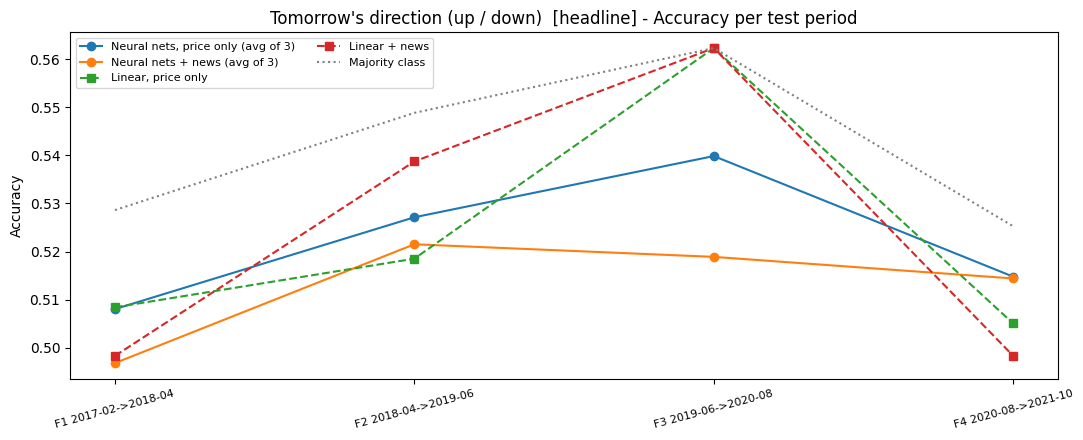

TOMORROW'S VOLATILITY VS THE 20-DAY AVERAGE RANGE  [HEADLINE]
Skill vs 20d avg by fold (neural nets: mean over 3 seeds)


Fold,F1 2017-02->2018-04,F2 2018-04->2019-06,F3 2019-06->2020-08,F4 2020-08->2021-10,Mean
Model,,,,,
LSTM,0.1625,0.1899,0.1681,0.0864,0.1517
Enhanced LSTM,0.1606,0.1387,0.1351,0.0862,0.1302
Transformer,0.1592,0.2064,0.1362,0.0999,0.1504
Enhanced Transformer,0.1653,0.1680,0.1210,0.0751,0.1324
GRU,0.1536,0.1637,0.1420,0.1031,0.1406
Enhanced GRU,0.1503,0.1684,0.1436,0.0817,0.1360
Linear,0.1484,0.1446,0.1499,0.0936,0.1341
Enhanced Linear,0.1433,0.1742,0.1336,0.0581,0.1273
20-day avg range,0.0000,0.0000,0.0000,0.0000,0.0000


Seed-to-seed SD of that metric (averaged over folds): {'LSTM': 0.0141, 'Enhanced LSTM': 0.0192, 'Transformer': 0.0089, 'Enhanced Transformer': 0.0123, 'GRU': 0.0066, 'Enhanced GRU': 0.0104}
Effect of adding news, fold by fold


,Model family,Mean change in Skill vs 20d avg (news - price only),Folds where news is better
0,LSTM,-0.0215,0 of 4
1,Transformer,-0.0181,1 of 4
2,GRU,-0.0046,2 of 4
3,Linear,-0.0068,1 of 4


Pooled block-bootstrap test (loss = squared error; positive = news helps; seed-averaged predictions)


,Model family,Mean loss reduction from news,95% CI low,95% CI high,Verdict
0,LSTM,-0.00361,-0.00664,-0.00080,news WORSE
1,Transformer,-0.00345,-0.00744,0.00045,no clear difference
2,GRU,-0.00081,-0.00362,0.00183,no clear difference
3,Linear,-0.00149,-0.00531,0.00277,no clear difference


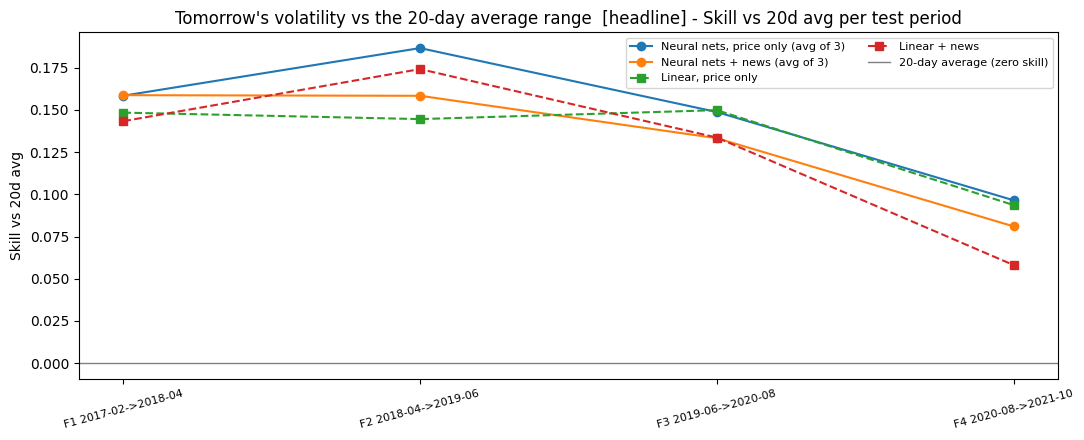

DIRECTION 5 TRADING DAYS AHEAD  [SECONDARY / EXPLORATORY]
Accuracy by fold (neural nets: mean over 3 seeds)


Fold,F1 2017-02->2018-04,F2 2018-04->2019-06,F3 2019-06->2020-08,F4 2020-08->2021-10,Mean
Model,,,,,
LSTM,0.5679,0.5701,0.7160,0.5612,0.6038
Enhanced LSTM,0.5039,0.5713,0.6970,0.5241,0.5741
Transformer,0.5129,0.5309,0.5937,0.5466,0.5460
Enhanced Transformer,0.4646,0.5690,0.6375,0.5264,0.5494
GRU,0.5107,0.5084,0.7093,0.5589,0.5718
Enhanced GRU,0.4478,0.5668,0.6420,0.5432,0.5499
Linear,0.6162,0.5758,0.7172,0.5623,0.6178
Enhanced Linear,0.5051,0.5859,0.7172,0.5623,0.5926
Majority class,0.6128,0.5859,0.7172,0.5623,0.6195


Seed-to-seed SD of that metric (averaged over folds): {'LSTM': 0.0163, 'Enhanced LSTM': 0.0374, 'Transformer': 0.0562, 'Enhanced Transformer': 0.0368, 'GRU': 0.0295, 'Enhanced GRU': 0.0496}
AUC averaged over folds: {'LSTM': 0.442, 'Enhanced LSTM': 0.469, 'Transformer': 0.473, 'Enhanced Transformer': 0.449, 'GRU': 0.454, 'Enhanced GRU': 0.466, 'Linear': 0.477, 'Enhanced Linear': 0.471, 'Majority class': 0.5, 'Same as last 5 days': 0.525}
Effect of adding news, fold by fold


,Model family,Mean change in Accuracy (news - price only),Folds where news is better
0,LSTM,-0.0297,1 of 4
1,Transformer,0.0034,2 of 4
2,GRU,-0.0219,1 of 4
3,Linear,-0.0253,1 of 4


Pooled block-bootstrap test (loss = log loss; positive = news helps; seed-averaged predictions)


,Model family,Mean loss reduction from news,95% CI low,95% CI high,Verdict
0,LSTM,-0.01202,-0.02116,-0.00033,news WORSE
1,Transformer,-0.00671,-0.01745,0.00564,no clear difference
2,GRU,0.00412,-0.00701,0.01700,no clear difference
3,Linear,-0.00194,-0.00506,0.00216,no clear difference


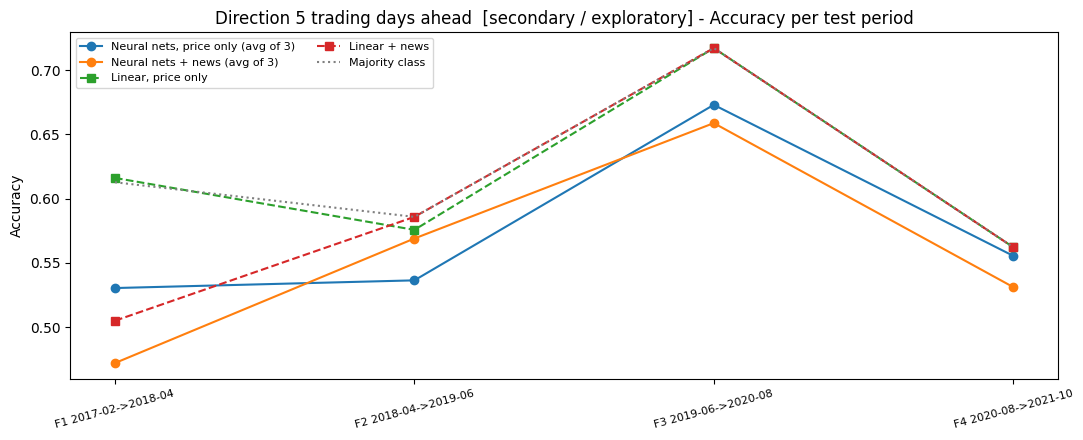

In [13]:
def build_results(fold_ids):
    rows = []
    for (k, task, name, seed), pred in PRED.items():
        if k in fold_ids:
            rows.append({"Fold": FOLDS[k]["label"], "Task": task, "Model": name, "Seed": seed, **score(task, k, pred)})
    for k in fold_ids:
        for task in TASKS:
            for nm, pred in simple_baselines(task, k).items():
                rows.append({"Fold": FOLDS[k]["label"], "Task": task, "Model": nm, "Seed": np.nan, **score(task, k, pred)})
    return pd.DataFrame(rows)

def ensemble(k, task, name):
    preds = [p for (kk, tt, nm, s), p in PRED.items() if kk == k and tt == task and nm == name]
    return np.mean(preds, axis=0)

def day_loss(task, y, p):
    if task == "vol1":
        return (y - p) ** 2
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def block_bootstrap_ci(d, block=20, n_boot=2000, seed=0):
    d = np.asarray(d, dtype=float); m = len(d)
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(m / block))
    starts_ = rng.integers(0, m - block + 1, size=(n_boot, n_blocks))
    idx = (starts_[:, :, None] + np.arange(block)[None, None, :]).reshape(n_boot, -1)[:, :m]
    means = d[idx].mean(axis=1)
    return d.mean(), np.percentile(means, [2.5, 97.5])

def report(fold_ids):
    res = build_results(fold_ids)
    labels = [FOLDS[k]["label"] for k in fold_ids]
    for task in TASKS:
        main = HEADLINE[task]
        print("=" * 100); print(TITLE[task].upper()); print("=" * 100)
        t = res[res.Task == task].groupby(["Model", "Fold"])[main].mean().unstack("Fold")[labels]
        t["Mean"] = t.mean(axis=1)
        t = t.reindex([nm for nm in DISPLAY_ORDER if nm in t.index])
        print(f"{main} by fold (neural nets: mean over {len(SEEDS)} seeds)"); display(t.round(4))
        nn_rows = res[(res.Task == task) & res.Model.isin(MODEL_NAMES)]
        sd = nn_rows.groupby(["Model", "Fold"])[main].std().groupby("Model").mean().reindex(MODEL_NAMES)
        print("Seed-to-seed SD of that metric (averaged over folds):", sd.round(4).to_dict())
        if task != "vol1":
            auc = res[res.Task == task].groupby(["Model", "Fold"])["AUC"].mean().groupby("Model").mean()
            print("AUC averaged over folds:", auc.reindex([nm for nm in DISPLAY_ORDER if nm in auc.index]).round(3).to_dict())

        eff = []
        for fam in FAMILIES:
            diff = t.loc[f"Enhanced {fam}", labels] - t.loc[fam, labels]
            eff.append({"Model family": fam, f"Mean change in {main} (news - price only)": diff.mean(),
                        "Folds where news is better": f"{int((diff > 0).sum())} of {len(labels)}"})
        print("Effect of adding news, fold by fold"); display(pd.DataFrame(eff).round(4))

        boot = []
        for fam in FAMILIES:
            d = []
            for k in fold_ids:
                y = Y[task][FOLDS[k]["test"]]
                d.append(day_loss(task, y, ensemble(k, task, fam)) - day_loss(task, y, ensemble(k, task, f"Enhanced {fam}")))
            mean_d, (lo, hi) = block_bootstrap_ci(np.concatenate(d))
            verdict = "news better" if lo > 0 else "news WORSE" if hi < 0 else "no clear difference"
            boot.append({"Model family": fam, "Mean loss reduction from news": mean_d, "95% CI low": lo, "95% CI high": hi, "Verdict": verdict})
        loss_name = "squared error" if task == "vol1" else "log loss"
        print(f"Pooled block-bootstrap test (loss = {loss_name}; positive = news helps; seed-averaged predictions)")
        display(pd.DataFrame(boot).round(5))

        x = np.arange(len(labels)); fig, ax = plt.subplots(figsize=(11, 4.5))
        ax.plot(x, t.loc[ARCHITECTURES, labels].mean(), "o-", label="Neural nets, price only (avg of 3)")
        ax.plot(x, t.loc[[f"Enhanced {a}" for a in ARCHITECTURES], labels].mean(), "o-", label="Neural nets + news (avg of 3)")
        ax.plot(x, t.loc["Linear", labels], "s--", label="Linear, price only")
        ax.plot(x, t.loc["Enhanced Linear", labels], "s--", label="Linear + news")
        if task == "vol1":
            ax.axhline(0, color="grey", lw=1, label="20-day average (zero skill)")
        else:
            ax.plot(x, t.loc["Majority class", labels], ":", color="grey", label="Majority class")
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15, fontsize=8)
        ax.set_ylabel(main); ax.set_title(f"{TITLE[task]} - {main} per test period")
        ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
    return res

dev_results = report(list(range(N_FOLDS - 1)))
dev_results.to_csv("AAPL_WF_Development_Per_Run.csv", index=False)

## 9. Final test (run once, after all decisions are frozen)

Set `RUN_FINAL_TEST = True` in the setup cell **only** when you have finished changing features, models and settings. This trains on everything before the last block and evaluates on it (roughly the last 12% of days). Do not go back and tune after looking at it. The pickle file means the development folds are not retrained.

F5 2021-10->2022-12 FINAL done | 178s | total predictions stored: 300
TOMORROW'S DIRECTION (UP / DOWN)  [HEADLINE]
Accuracy by fold (neural nets: mean over 3 seeds)


Fold,F5 2021-10->2022-12 FINAL,Mean
Model,,
LSTM,0.4792,0.4792
Enhanced LSTM,0.4882,0.4882
Transformer,0.4860,0.4860
Enhanced Transformer,0.4680,0.4680
GRU,0.4848,0.4848
Enhanced GRU,0.4826,0.4826
Linear,0.4882,0.4882
Enhanced Linear,0.4916,0.4916
Majority class,0.4848,0.4848


Seed-to-seed SD of that metric (averaged over folds): {'LSTM': 0.0085, 'Enhanced LSTM': 0.0034, 'Transformer': 0.0216, 'Enhanced Transformer': 0.0309, 'GRU': 0.0321, 'Enhanced GRU': 0.0078}
AUC averaged over folds: {'LSTM': 0.465, 'Enhanced LSTM': 0.465, 'Transformer': 0.48, 'Enhanced Transformer': 0.46, 'GRU': 0.481, 'Enhanced GRU': 0.475, 'Linear': 0.467, 'Enhanced Linear': 0.476, 'Majority class': 0.5, 'Same as today': 0.505}
Effect of adding news, fold by fold


,Model family,Mean change in Accuracy (news - price only),Folds where news is better
0,LSTM,0.0090,1 of 1
1,Transformer,-0.0180,0 of 1
2,GRU,-0.0022,0 of 1
3,Linear,0.0034,1 of 1


Pooled block-bootstrap test (loss = log loss; positive = news helps; seed-averaged predictions)


,Model family,Mean loss reduction from news,95% CI low,95% CI high,Verdict
0,LSTM,-0.00217,-0.00416,0.00050,no clear difference
1,Transformer,-0.00659,-0.01397,0.00146,no clear difference
2,GRU,-0.00172,-0.00367,0.00000,no clear difference
3,Linear,0.00031,-0.00080,0.00112,no clear difference


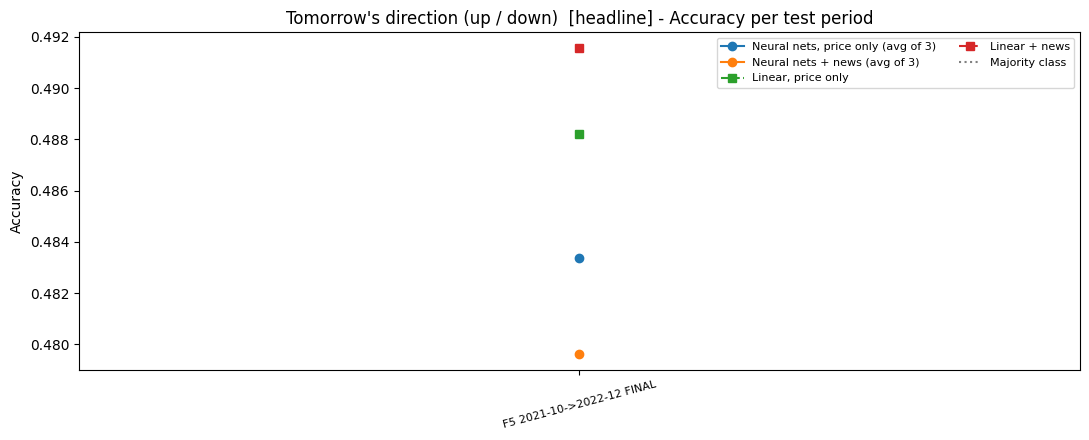

TOMORROW'S VOLATILITY VS THE 20-DAY AVERAGE RANGE  [HEADLINE]
Skill vs 20d avg by fold (neural nets: mean over 3 seeds)


Fold,F5 2021-10->2022-12 FINAL,Mean
Model,,
LSTM,0.1479,0.1479
Enhanced LSTM,0.1459,0.1459
Transformer,0.1541,0.1541
Enhanced Transformer,0.1588,0.1588
GRU,0.1705,0.1705
Enhanced GRU,0.1656,0.1656
Linear,0.1901,0.1901
Enhanced Linear,0.1283,0.1283
20-day avg range,0.0000,0.0000


Seed-to-seed SD of that metric (averaged over folds): {'LSTM': 0.0262, 'Enhanced LSTM': 0.0155, 'Transformer': 0.0072, 'Enhanced Transformer': 0.0266, 'GRU': 0.0076, 'Enhanced GRU': 0.0013}
Effect of adding news, fold by fold


,Model family,Mean change in Skill vs 20d avg (news - price only),Folds where news is better
0,LSTM,-0.0020,0 of 1
1,Transformer,0.0047,1 of 1
2,GRU,-0.0049,0 of 1
3,Linear,-0.0618,0 of 1


Pooled block-bootstrap test (loss = squared error; positive = news helps; seed-averaged predictions)


,Model family,Mean loss reduction from news,95% CI low,95% CI high,Verdict
0,LSTM,-0.00090,-0.00462,0.00416,no clear difference
1,Transformer,0.00181,-0.00112,0.00497,no clear difference
2,GRU,-0.00236,-0.00539,0.00186,no clear difference
3,Linear,-0.00969,-0.01864,-0.00101,news WORSE


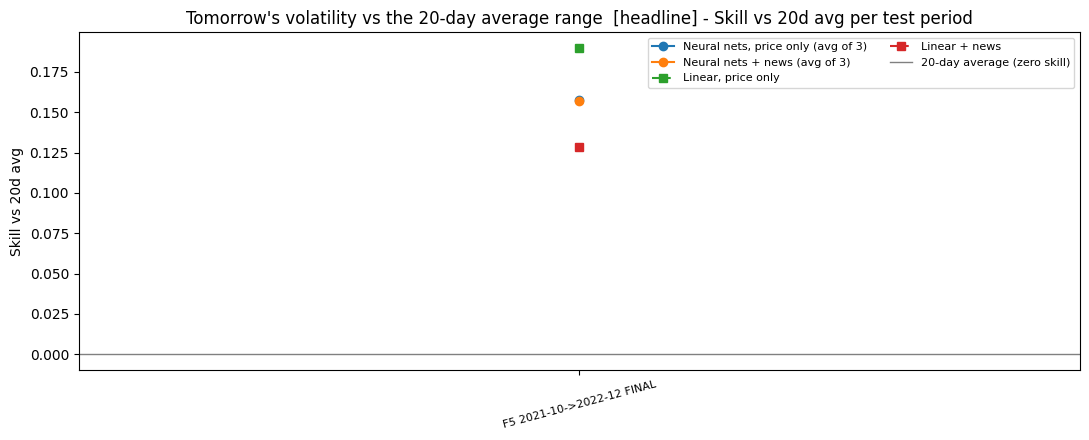

DIRECTION 5 TRADING DAYS AHEAD  [SECONDARY / EXPLORATORY]
Accuracy by fold (neural nets: mean over 3 seeds)


Fold,F5 2021-10->2022-12 FINAL,Mean
Model,,
LSTM,0.4613,0.4613
Enhanced LSTM,0.4613,0.4613
Transformer,0.4489,0.4489
Enhanced Transformer,0.4714,0.4714
GRU,0.4602,0.4602
Enhanced GRU,0.4646,0.4646
Linear,0.4613,0.4613
Enhanced Linear,0.4613,0.4613
Majority class,0.4613,0.4613


Seed-to-seed SD of that metric (averaged over folds): {'LSTM': 0.0, 'Enhanced LSTM': 0.0, 'Transformer': 0.0118, 'Enhanced Transformer': 0.0236, 'GRU': 0.0019, 'Enhanced GRU': 0.0154}
AUC averaged over folds: {'LSTM': 0.492, 'Enhanced LSTM': 0.539, 'Transformer': 0.477, 'Enhanced Transformer': 0.502, 'GRU': 0.484, 'Enhanced GRU': 0.5, 'Linear': 0.516, 'Enhanced Linear': 0.52, 'Majority class': 0.5, 'Same as last 5 days': 0.571}
Effect of adding news, fold by fold


,Model family,Mean change in Accuracy (news - price only),Folds where news is better
0,LSTM,0.0000,0 of 1
1,Transformer,0.0224,1 of 1
2,GRU,0.0045,1 of 1
3,Linear,0.0000,0 of 1


Pooled block-bootstrap test (loss = log loss; positive = news helps; seed-averaged predictions)


,Model family,Mean loss reduction from news,95% CI low,95% CI high,Verdict
0,LSTM,0.00581,0.00019,0.01174,news better
1,Transformer,0.01077,-0.00238,0.02526,no clear difference
2,GRU,0.00754,-0.00168,0.01441,no clear difference
3,Linear,0.00665,-0.00004,0.01248,no clear difference


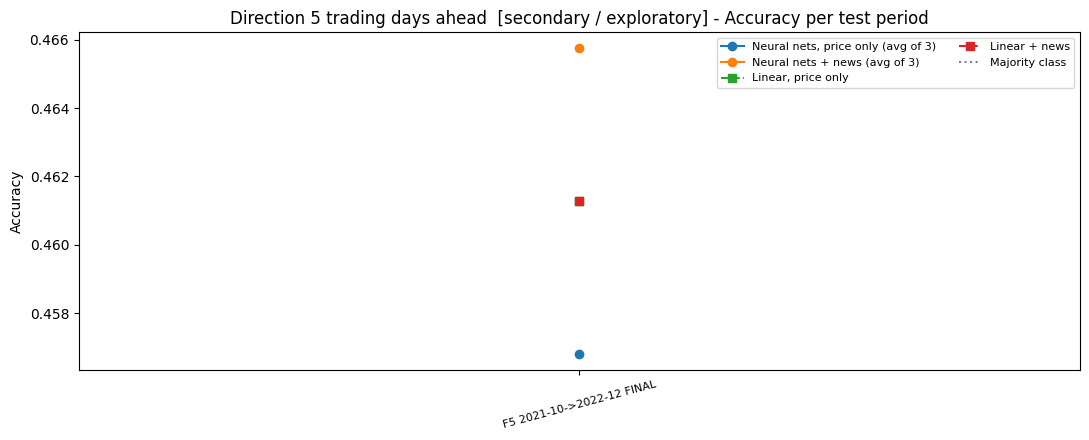

Direction accuracy on 297 test days has a standard error of about 2.9 percentage points, so gaps of a few points are noise.


In [17]:
if RUN_FINAL_TEST:
    run_fold(N_FOLDS - 1)
    test_results = report([N_FOLDS - 1])
    test_results.to_csv("AAPL_WF_FinalTest_Per_Run.csv", index=False)
    n_test = len(FOLDS[-1]["test"])
    print(f"Direction accuracy on {n_test} test days has a standard error of about {np.sqrt(0.25 / n_test) * 100:.1f} "
          f"percentage points, so gaps of a few points are noise.")
else:
    print("Final test is reserved. Set RUN_FINAL_TEST = True when you are ready.")

## How to read the results (and what to write in the paper)

- **Volatility.** Look at *Skill vs 20d avg*. Persistence baselines (5-day average, today's range) and the linear model are the fair competitors for the neural networks. If news does not beat its price-only twin in the bootstrap test, say news adds no measurable information about tomorrow's volatility beyond price history.
- **Direction.** Compare against *Majority class*. Around 50-54% is normal; a standard error is about 2.5-3 points per fold. AUC near 0.50 means no ranking skill.
- **Secondary task (`dir5`).** Report it as exploratory. Overlapping 5-day windows make labels strongly autocorrelated, so intervals are optimistic; do not oversell small gains.
- **Fold table.** A result that only appears in one period (e.g. COVID) is weaker evidence than one that shows up in most folds. Fold 4 contains the 2020 crash.
- **Many tests, so beware of flukes.** There are 3 tasks x 4 model families = 12 news-vs-no-news tests, and each has a ~5% chance of a false 'news better' by luck (about 0.6 expected flukes in total). A single 'news better' cell means little. Trust only a *pattern*: the same direction across most folds, across architectures, in both the neural and linear models, and still present with `CONSERVATIVE_NEWS_LAG = True`.
- **Robustness.** Set `CONSERVATIVE_NEWS_LAG = True`, rerun, and check that conclusions do not change.

**Limitations to state:** one stock and one decade; dates without timestamps (same-day timing is an assumption); FinBERT sentiment from a mixed-source news file whose volume changes a lot over time; the final block is a different market regime than most of the training data; and a null result (news adds nothing) is a legitimate finding, not a failure.